# Linear Regression Health Costs Calculator

Goal: Mean Absolute Error below 3500 on the test set.

In [1]:
# Import libraries. You may or may not use all of these.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
try:
    %tensorflow_version 2.x
except Exception:
    pass
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.random.set_seed(42)
np.random.seed(42)

In [2]:
# Import data
import os
if os.path.exists('data/insurance.csv'):
    dataset = pd.read_csv('data/insurance.csv')
else:
    if not os.path.exists('insurance.csv'):
        !wget -q https://cdn.freecodecamp.org/project-data/health-costs/insurance.csv
    dataset = pd.read_csv('insurance.csv')
dataset.tail()

,age,sex,bmi,children,smoker,region,expenses
1333,50,male,31.0,3,no,northwest,10600.55
1334,18,female,31.9,0,no,northeast,2205.98
1335,18,female,36.9,0,no,southeast,1629.83
1336,21,female,25.8,0,no,southwest,2007.95
1337,61,female,29.1,0,yes,northwest,29141.36


In [3]:
# Pre-processing: one-hot encode the categorical columns and split 80/20.
dataset = pd.get_dummies(dataset, columns=['sex', 'smoker', 'region'], drop_first=True)

train_dataset = dataset.sample(frac=0.8, random_state=0)
test_dataset = dataset.drop(train_dataset.index)

train_labels = train_dataset.pop('expenses')
test_labels = test_dataset.pop('expenses')

normalizer = layers.Normalization(axis=-1)
normalizer.adapt(np.array(train_dataset))

In [4]:
model = keras.Sequential([
    normalizer,
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1),
])
model.compile(optimizer=keras.optimizers.Adam(0.01), loss='mae', metrics=['mae', 'mse'])
history = model.fit(train_dataset, train_labels, epochs=120, batch_size=32,
                    validation_split=0.2, verbose=0)
print('final train MAE:', history.history['mae'][-1])

final train MAE: 1594.9022216796875


9/9 - 0s - 24ms/step - loss: 2367.2383 - mae: 2367.2383 - mse: 33269912.0000


Testing set Mean Abs Error: 2367.24 expenses
You passed the challenge. Great job!


1/9 ━━━━━━━━━━━━━━━━━━━━ 1s 212ms/step

8/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step  

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step


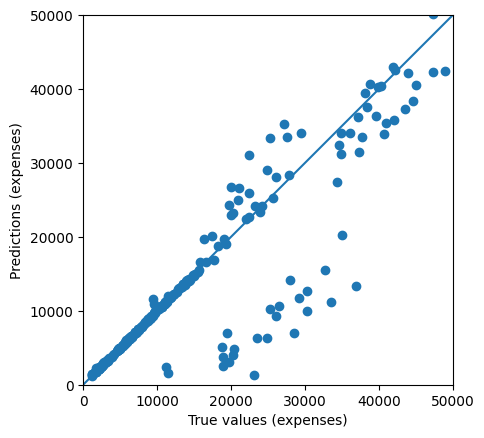

In [5]:
# RUN THIS CELL TO TEST YOUR MODEL. DO NOT MODIFY CONTENTS.
# Test model by checking how well the model generalizes using the test set.
loss, mae, mse = model.evaluate(test_dataset, test_labels, verbose=2)

print('Testing set Mean Abs Error: {:5.2f} expenses'.format(mae))

if mae < 3500:
    print('You passed the challenge. Great job!')
else:
    print('The Mean Abs Error must be less than 3500. Keep trying.')

# Plot predictions.
test_predictions = model.predict(test_dataset).flatten()

a = plt.axes(aspect='equal')
plt.scatter(test_labels, test_predictions)
plt.xlabel('True values (expenses)')
plt.ylabel('Predictions (expenses)')
lims = [0, 50000]
plt.xlim(lims)
plt.ylim(lims)
_ = plt.plot(lims, lims)
plt.show()